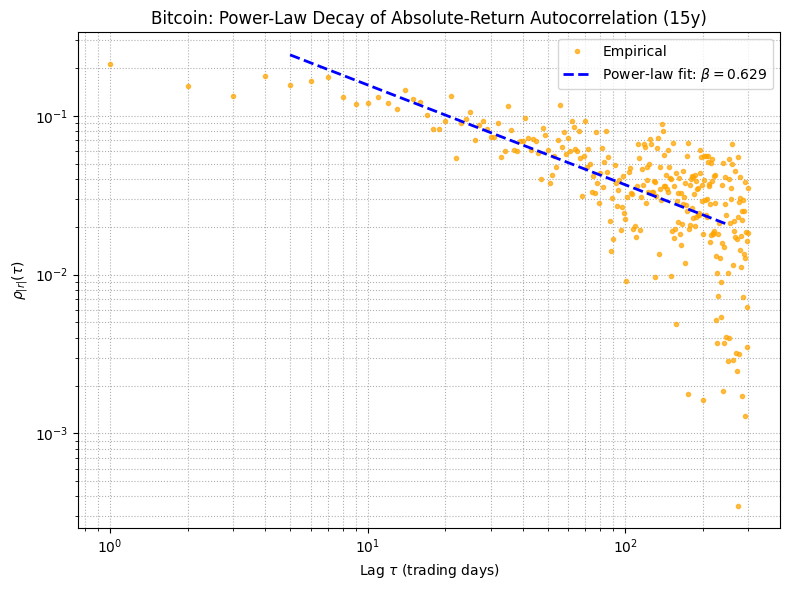

beta = 0.6288
R²    = 0.4336
Fit range: 5 to 250 lags


In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

ticker = "BTC-USD"
asset_name = "Bitcoin"


period = "15y"
max_lag = 1000

fit_min_lag = 5
fit_max_lag = 250
plot_max_lag = 300

# data

data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = data["Close"].squeeze().dropna()


# Log returns and absolute returns
returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)

# Autocorrelation of absolute returns
lags = np.arange(1, max_lag + 1)

acf_abs = np.array([
    abs_returns.autocorr(lag=lag)
    for lag in lags
])


# Power-law fit only on meaningful region
fit_mask = (
    (lags >= fit_min_lag) &
    (lags <= fit_max_lag) &
    (acf_abs > 0)
)

lags_fit = lags[fit_mask]
acf_fit = acf_abs[fit_mask]

slope, intercept, r_value, p_value, std_err = linregress(
    np.log(lags_fit),
    np.log(acf_fit)
)

beta = -slope
acf_powerlaw = np.exp(intercept) * lags_fit ** (-beta)

# Plot: log-log
plt.figure(figsize=(8, 6))

plot_mask = (
    (lags <= plot_max_lag) &
    (acf_abs > 0)
)

plt.loglog(
    lags[plot_mask],
    acf_abs[plot_mask],
    "o",
    ms=3,
    alpha=0.7,
    color="orange",
    label="Empirical"
)

plt.loglog(
    lags_fit,
    acf_powerlaw,
    "--",
    lw=2,
    color="blue",
    label=fr"Power-law fit: $\beta={beta:.3f}$"
)

plt.xlabel(r"Lag $\tau$ (trading days)")
plt.ylabel(r"$\rho_{|r|}(\tau)$")
plt.title(f"{asset_name}: Power-Law Decay of Absolute-Return Autocorrelation ({period})")
plt.legend()
plt.grid(True, which="both", linestyle=":")
plt.tight_layout()
plt.show()

print(f"beta = {beta:.4f}")
print(f"R²    = {r_value**2:.4f}")
print(f"Fit range: {fit_min_lag} to {fit_max_lag} lags")

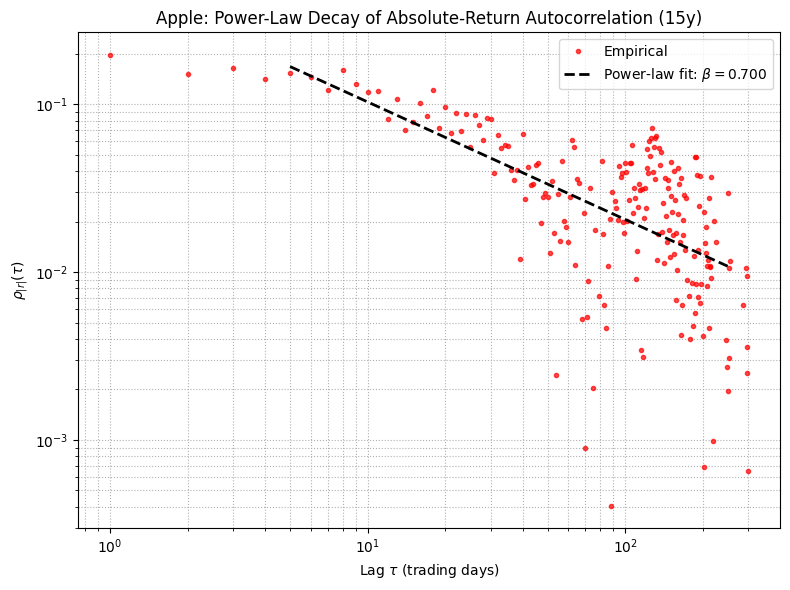

beta = 0.7001
R²    = 0.3224
Fit range: 5 to 250 lags


In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

ticker = "AAPL"
asset_name = "Apple"
period = "15y"
max_lag = 1000

fit_min_lag = 5
fit_max_lag = 250
plot_max_lag = 300

# data
data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = data["Close"].squeeze().dropna()


# Log returns and absolute returns
returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)

# Autocorrelation of absolute returns
lags = np.arange(1, max_lag + 1)

acf_abs = np.array([
    abs_returns.autocorr(lag=lag)
    for lag in lags
])

# Power-law fit only on meaningful region
fit_mask = (
    (lags >= fit_min_lag) &
    (lags <= fit_max_lag) &
    (acf_abs > 0)
)

lags_fit = lags[fit_mask]
acf_fit = acf_abs[fit_mask]

slope, intercept, r_value, p_value, std_err = linregress(
    np.log(lags_fit),
    np.log(acf_fit)
)

beta = -slope
acf_powerlaw = np.exp(intercept) * lags_fit ** (-beta)

# Plot: log-log
plt.figure(figsize=(8, 6))

plot_mask = (
    (lags <= plot_max_lag) &
    (acf_abs > 0)
)

plt.loglog(
    lags[plot_mask],
    acf_abs[plot_mask],
    "o",
    ms=3,
    alpha=0.7,
    color="red",
    label="Empirical"
)

plt.loglog(
    lags_fit,
    acf_powerlaw,
    "--",
    lw=2,
    color="black",
    label=fr"Power-law fit: $\beta={beta:.3f}$"
)

plt.xlabel(r"Lag $\tau$ (trading days)")
plt.ylabel(r"$\rho_{|r|}(\tau)$")
plt.title(f"{asset_name}: Power-Law Decay of Absolute-Return Autocorrelation ({period})")
plt.legend()
plt.grid(True, which="both", linestyle=":")
plt.tight_layout()
plt.show()

print(f"beta = {beta:.4f}")
print(f"R²    = {r_value**2:.4f}")
print(f"Fit range: {fit_min_lag} to {fit_max_lag} lags")

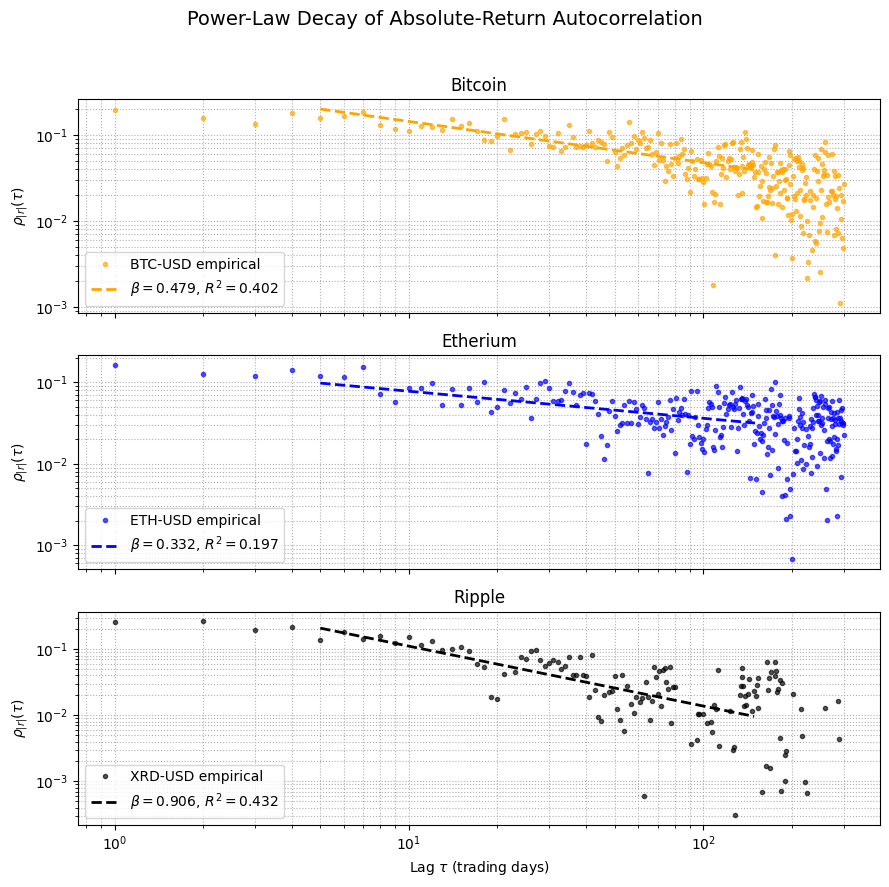

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

tickers = {
    "Bitcoin": ("BTC-USD", "orange"),
    "Etherium": ("ETH-USD", "blue"),
    "Ripple": ("XRD-USD", "black"),
}

period = "10y"
max_lag = 500
fit_min_lag = 5
fit_max_lag = 150
plot_max_lag = 300

# figure

fig, axes = plt.subplots(len(tickers), 1, figsize=(9, 9), sharex=True)

for ax, (name, (ticker, color)) in zip(axes, tickers.items()):

    data = yf.download(
        ticker,
        period=period,
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    prices = data["Close"].squeeze().dropna()
    returns = np.log(prices / prices.shift(1)).dropna()
    abs_returns = np.abs(returns)

    lags = np.arange(1, max_lag + 1)

    acf_abs = np.array([
        abs_returns.autocorr(lag=lag)
        for lag in lags
    ])

    fit_mask = (
        (lags >= fit_min_lag) &
        (lags <= fit_max_lag) &
        (acf_abs > 0)
    )

    lags_fit = lags[fit_mask]
    acf_fit = acf_abs[fit_mask]

    slope, intercept, r_value, p_value, std_err = linregress(
        np.log(lags_fit),
        np.log(acf_fit)
    )

    beta = -slope
    acf_powerlaw = np.exp(intercept) * lags_fit ** (-beta)

    plot_mask = (lags <= plot_max_lag) & (acf_abs > 0)

    ax.loglog(
        lags[plot_mask],
        acf_abs[plot_mask],
        "o",
        ms=3,
        alpha=0.65,
        color=color,
        label=f"{ticker} empirical"
    )

    ax.loglog(
        lags_fit,
        acf_powerlaw,
        "--",
        linewidth=2,
        color=color,
        label=fr"$\beta={beta:.3f}$, $R^2={r_value**2:.3f}$"
    )

    ax.set_ylabel(r"$\rho_{|r|}(\tau)$")
    ax.set_title(name)
    ax.legend()
    ax.grid(True, which="both", linestyle=":")

axes[-1].set_xlabel(r"Lag $\tau$ (trading days)")

plt.suptitle("Power-Law Decay of Absolute-Return Autocorrelation", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

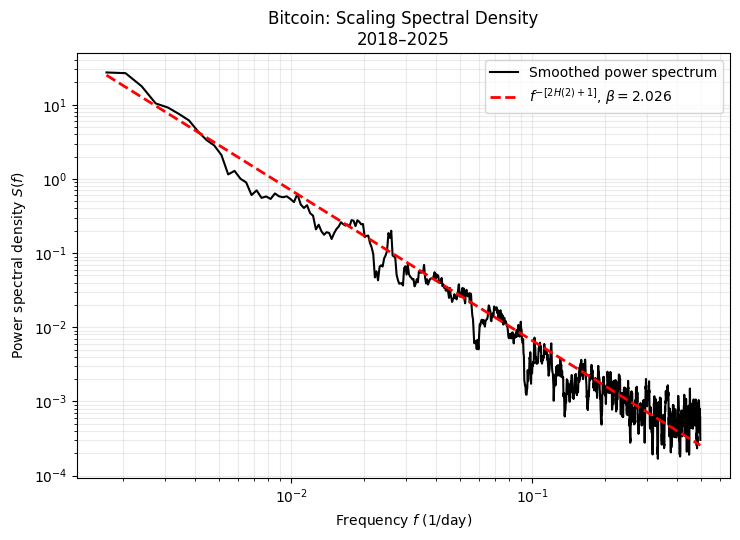

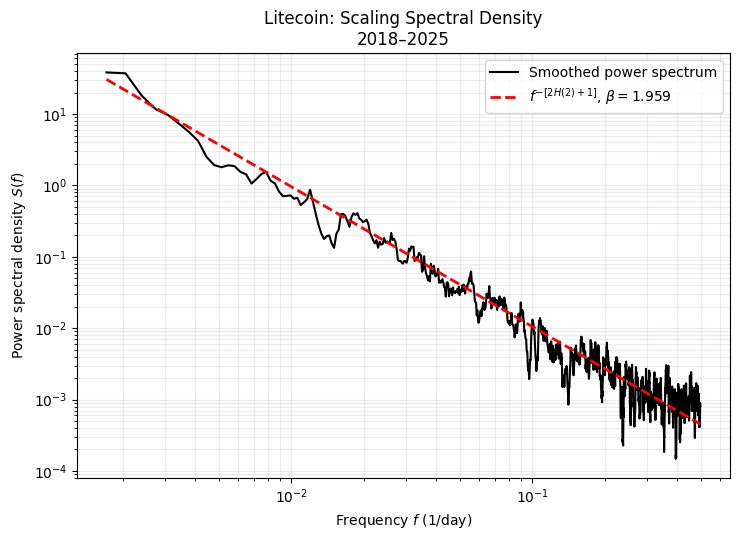

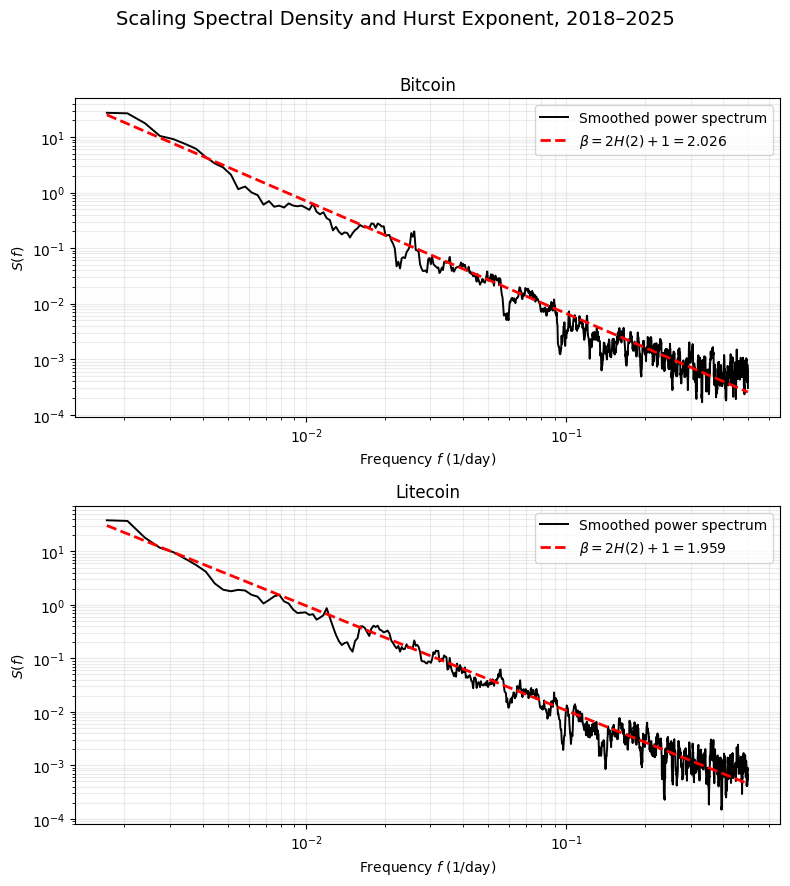

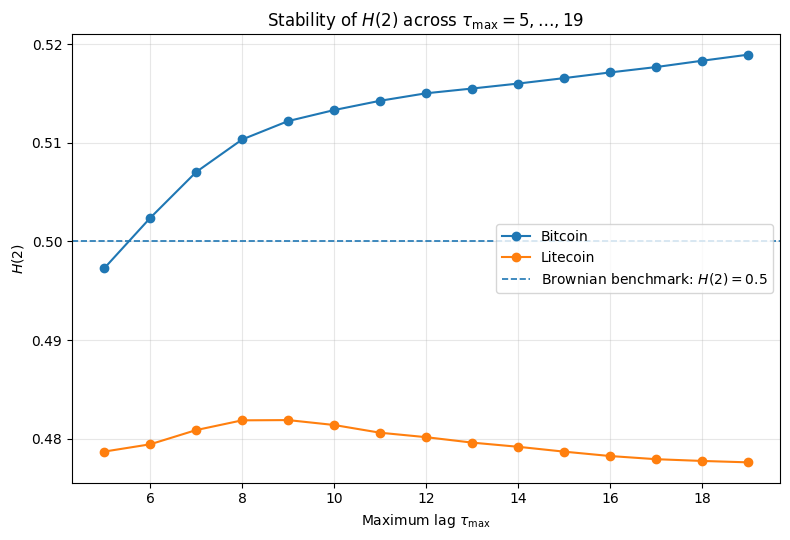


DI MATTEO-STYLE GHE AND SPECTRAL ANALYSIS

Bitcoin (BTC-USD)
------------------------------------------------------------------------
Observations          : 2922
H(2)                  : 0.5128 ± 0.0062
Mean GHE R²           : 0.9993
beta = 2H(2) + 1      : 2.0256

Litecoin (LTC-USD)
------------------------------------------------------------------------
Observations          : 2922
H(2)                  : 0.4796 ± 0.0015
Mean GHE R²           : 0.9999
beta = 2H(2) + 1      : 1.9592


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.signal import periodogram
from scipy.stats import linregress

# Parameters

assets = {
    "Bitcoin": "BTC-USD",
    "Litecoin": "LTC-USD",
}

START_DATE = "2018-01-01"
END_DATE = "2026-01-01" 

Q = 2

# Di Matteo uses tau_max values from 5 to 19
TAU_MAX_VALUES = range(5, 20)

# PSD visualization
PSD_MIN_FREQ = 1e-4
PSD_MAX_FREQ = 0.5

# Smoothing is only for visual clarity
SMOOTHING_WINDOW = 9


# Download 
def download_prices(ticker, start_date, end_date):
    data = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=True,
        progress=False,
    )

    if data.empty:
        raise ValueError(f"No data downloaded for {ticker}.")

    prices = data["Close"]

    # Handle possible yfinance MultiIndex output
    if isinstance(prices, pd.DataFrame):
        prices = prices.iloc[:, 0]

    prices = (
        pd.to_numeric(prices.squeeze(), errors="coerce")
        .dropna()
    )

    if len(prices) < 100:
        raise ValueError(
            f"Insufficient data for {ticker}: {len(prices)} observations."
        )

    return prices


# Linear detrending
#

def detrend_log_price(prices):
    x = np.log(prices.to_numpy(dtype=float))
    t = np.arange(len(x), dtype=float)

    slope, intercept, _, _, _ = linregress(t, x)
    trend = intercept + slope * t

    return x - trend


# ============================================================
# Estimate H(2) for one selected tau_max
#
# K_q(tau) =
# E[|X(t+tau)-X(t)|^q] / E[|X(t)|^q]
#
# K_q(tau) ~ tau^[qH(q)]
# ============================================================
def estimate_h2_for_tau_max(x, tau_max, q=2):
    taus = np.arange(1, tau_max + 1)

    denominator = np.mean(np.abs(x) ** q)

    if denominator <= 0 or not np.isfinite(denominator):
        raise ValueError("Invalid GHE denominator.")

    kq = []

    for tau in taus:
        increments = x[tau:] - x[:-tau]

        moment = np.mean(np.abs(increments) ** q)
        kq.append(moment / denominator)

    kq = np.asarray(kq, dtype=float)

    valid = (
        np.isfinite(kq)
        & (kq > 0)
    )

    regression = linregress(
        np.log(taus[valid]),
        np.log(kq[valid]),
    )

    h2 = regression.slope / q

    return {
        "tau_max": tau_max,
        "H2": h2,
        "R2": regression.rvalue ** 2,
    }


# Estimate average H(2) over tau_max = 5,...,19
def estimate_generalized_hurst(x, q=2):
    estimates = []

    for tau_max in TAU_MAX_VALUES:
        result = estimate_h2_for_tau_max(
            x=x,
            tau_max=tau_max,
            q=q,
        )
        estimates.append(result)

    h2_values = np.array(
        [result["H2"] for result in estimates],
        dtype=float,
    )

    r2_values = np.array(
        [result["R2"] for result in estimates],
        dtype=float,
    )

    h2_mean = np.mean(h2_values)
    h2_std = np.std(h2_values, ddof=1)

    beta = 2 * h2_mean + 1

    return {
        "H2": h2_mean,
        "H2_std": h2_std,
        "beta": beta,
        "mean_R2": np.mean(r2_values),
        "estimates": estimates,
    }

# Power spectral density of detrended log-price
def calculate_psd(x):
    frequencies, psd = periodogram(
        x,
        fs=1.0,              # one observation per calendar day
        detrend=False,       # x has already been linearly detrended
        scaling="density",
        window="boxcar",
    )

    valid = (
        (frequencies > 0)
        & (psd > 0)
        & np.isfinite(frequencies)
        & np.isfinite(psd)
    )

    frequencies = frequencies[valid]
    psd = psd[valid]

    frequency_mask = (
        (frequencies >= PSD_MIN_FREQ)
        & (frequencies <= PSD_MAX_FREQ)
    )

    frequencies = frequencies[frequency_mask]
    psd = psd[frequency_mask]

    return frequencies, psd


# ============================================================
# Smooth PSD in logarithmic space
#
# Used only to make the scaling behavior easier to see.
# It does not determine beta.
# ============================================================
def smooth_psd_logspace(frequencies, psd, window=9):
    if window < 1 or window % 2 == 0:
        raise ValueError("Smoothing window must be a positive odd integer.")

    if len(psd) <= window:
        raise ValueError("PSD series is too short for smoothing.")

    log_psd = np.log10(psd)

    kernel = np.ones(window) / window
    smoothed_log_psd = np.convolve(
        log_psd,
        kernel,
        mode="same",
    )

    edge = window // 2

    frequencies_smooth = frequencies[edge:-edge]
    psd_smooth = 10 ** smoothed_log_psd[edge:-edge]

    return frequencies_smooth, psd_smooth

# ============================================================
# Position the theoretical f^(-beta) line
#
# The slope beta is fixed by:
# beta = 2H(2) + 1
#
# Only the vertical intercept is fitted.
# ============================================================
def theoretical_psd_line(frequencies, empirical_psd, beta):
    log_frequency = np.log10(frequencies)
    log_psd = np.log10(empirical_psd)

    log_intercept = np.mean(
        log_psd + beta * log_frequency
    )

    intercept = 10 ** log_intercept

    return intercept * frequencies ** (-beta)


# ============================================================
# Main analysis
# ============================================================
results = {}

for asset_name, ticker in assets.items():
    prices = download_prices(
        ticker=ticker,
        start_date=START_DATE,
        end_date=END_DATE,
    )

    x_detrended = detrend_log_price(prices)

    ghe = estimate_generalized_hurst(
        x=x_detrended,
        q=Q,
    )

    frequencies, psd = calculate_psd(x_detrended)

    frequencies_smooth, psd_smooth = smooth_psd_logspace(
        frequencies=frequencies,
        psd=psd,
        window=SMOOTHING_WINDOW,
    )

    theoretical_line = theoretical_psd_line(
        frequencies=frequencies_smooth,
        empirical_psd=psd_smooth,
        beta=ghe["beta"],
    )

    results[asset_name] = {
        "ticker": ticker,
        "prices": prices,
        "H2": ghe["H2"],
        "H2_std": ghe["H2_std"],
        "beta": ghe["beta"],
        "mean_R2": ghe["mean_R2"],
        "estimates": ghe["estimates"],
        "frequencies": frequencies_smooth,
        "psd": psd_smooth,
        "theoretical_line": theoretical_line,
    }


# ============================================================
# PSD plots
# ============================================================
for asset_name, result in results.items():
    plt.figure(figsize=(7.5, 5.5))

    plt.loglog(
        result["frequencies"],
        result["psd"],
        color="black",
        linewidth=1.5,
        label="Smoothed power spectrum",
    )

    plt.loglog(
        result["frequencies"],
        result["theoretical_line"],
        "r--",
        linewidth=2,
        label=(
            rf"$f^{{-[2H(2)+1]}}$, "
            rf"$\beta={result['beta']:.3f}$"
        ),
    )

    plt.xlabel(r"Frequency $f$ (1/day)")
    plt.ylabel(r"Power spectral density $S(f)$")
    plt.title(
        f"{asset_name}: Scaling Spectral Density\n"
        f"2018–2025"
    )

    plt.grid(True, which="both", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# combined plot
# ============================================================
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8, 9),
)

for ax, (asset_name, result) in zip(axes, results.items()):
    ax.loglog(
        result["frequencies"],
        result["psd"],
        color="black",
        linewidth=1.4,
        label="Smoothed power spectrum",
    )

    ax.loglog(
        result["frequencies"],
        result["theoretical_line"],
        "r--",
        linewidth=2,
        label=(
            rf"$\beta=2H(2)+1={result['beta']:.3f}$"
        ),
    )

    ax.set_title(asset_name)
    ax.set_xlabel(r"Frequency $f$ (1/day)")
    ax.set_ylabel(r"$S(f)$")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()

plt.suptitle(
    "Scaling Spectral Density and Hurst Exponent, 2018–2025",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ============================================================
# Stability plot for H(2)
# ============================================================
plt.figure(figsize=(8, 5.5))

for asset_name, result in results.items():
    tau_max_values = [
        item["tau_max"]
        for item in result["estimates"]
    ]

    h2_values = [
        item["H2"]
        for item in result["estimates"]
    ]

    plt.plot(
        tau_max_values,
        h2_values,
        marker="o",
        linewidth=1.5,
        label=asset_name,
    )

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.2,
    label=r"Brownian benchmark: $H(2)=0.5$",
)

plt.xlabel(r"Maximum lag $\tau_{\max}$")
plt.ylabel(r"$H(2)$")
plt.title(r"Stability of $H(2)$ across $\tau_{\max}=5,\ldots,19$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Results summary
# ============================================================
print("\n" + "=" * 72)
print("DI MATTEO-STYLE GHE AND SPECTRAL ANALYSIS")
print("=" * 72)

for asset_name, result in results.items():
    print(f"\n{asset_name} ({result['ticker']})")
    print("-" * 72)
    print(f"Observations          : {len(result['prices'])}")
    print(
        f"H(2)                  : "
        f"{result['H2']:.4f} ± {result['H2_std']:.4f}"
    )
    print(
        f"Mean GHE R²           : "
        f"{result['mean_R2']:.4f}"
    )
    print(
        f"beta = 2H(2) + 1      : "
        f"{result['beta']:.4f}"
    )

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


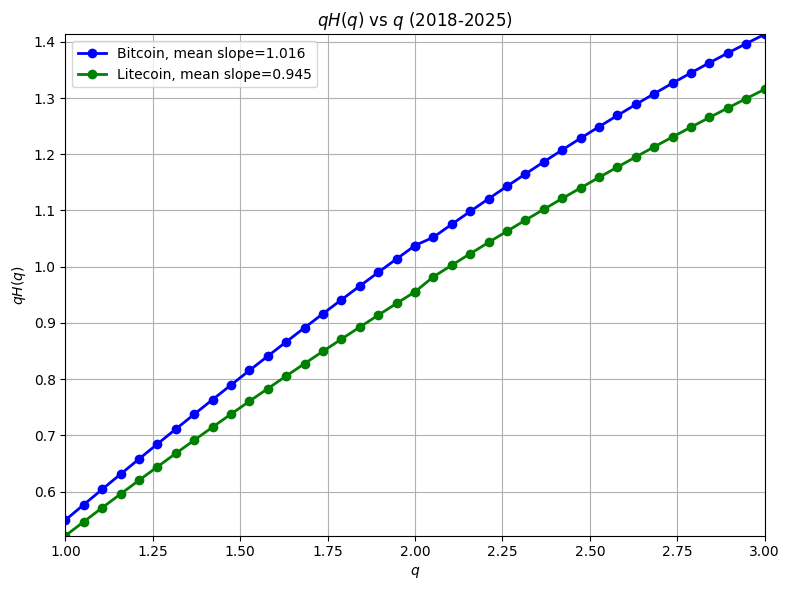

In [ ]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters
start = "2018-01-01"
end   = "2025-12-31"

# q ranges
q_low  = np.linspace(1.0, 2.0, 20)
q_high = np.linspace(2.0, 3.0, 20)
qs = np.concatenate([q_low, q_high])

# tau ranges (q-dependent)
tau_low  = np.arange(1, 19)
tau_high = np.arange(1, 12)

markets = {
    "Bitcoin": ("BTC-USD", "blue"),
    "Litecoin": ("LTC-USD", "green")
}


# GHE estimator
def generalized_hurst_Kq(log_prices, q, taus):
    X = log_prices.values
    denom = np.mean(np.abs(X) ** q)
    Kq = []

    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)

# Plot qH(q) vs q
plt.figure(figsize=(8, 6))

all_qHq = []

for label, (ticker, color) in markets.items():
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna()
    log_prices = np.log10(prices)
    log_prices -= log_prices.mean()

    qHq = []

    for q in qs:
        taus = tau_low if q <= 2 else tau_high
        Kq = generalized_hurst_Kq(log_prices, q, taus)

        x = np.log10(taus)
        y = np.log10(Kq)

        slope, _, _, _, _ = linregress(x, y)
        qHq.append(slope)

    qHq = np.array(qHq)
    all_qHq.append(qHq)

    plt.plot(
        qs,
        qHq,
        marker="o",
        linewidth=2,
        color=color,
        label=f"{label}, mean slope={qHq.mean():.3f}"
    )

# Axis ranges
all_qHq = np.concatenate(all_qHq)

plt.xlim(qs.min(), qs.max())
plt.ylim(all_qHq.min(), all_qHq.max())

plt.xlabel(r"$q$")
plt.ylabel(r"$qH(q)$")
plt.title(r"$qH(q)$ vs $q$ (2018-2025)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
